# Car Price Prediction

import the Required Python Libraries

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
df=pd.read_csv(r"C:\Users\Lenovo\Downloads\car data.csv")
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [69]:
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [70]:
df.isna().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Analysis on Car Data

In [71]:
total_cars=df.groupby("Car_Name")["Car_Name"].value_counts().sort_values(ascending=False).head(10)
print(total_cars)

Car_Name
city                         26
corolla altis                16
verna                        14
fortuner                     11
brio                         10
innova                        9
i20                           9
ciaz                          9
grand i10                     8
Royal Enfield Classic 350     7
Name: count, dtype: int64


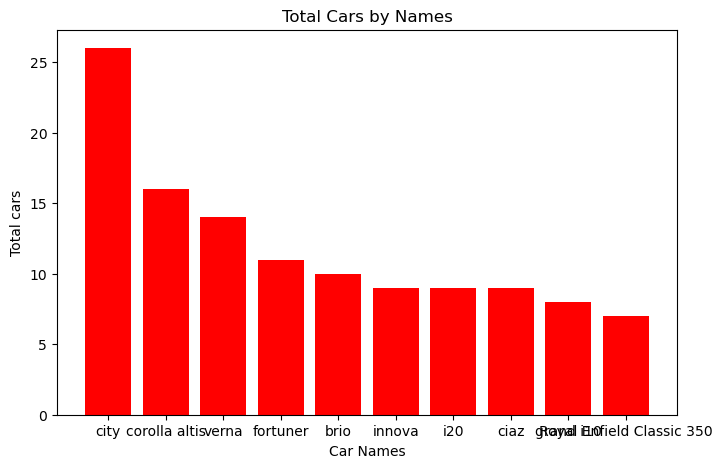

In [72]:
plt.figure(figsize=(8,5))
plt.bar(total_cars.index,total_cars.values,color='r')
plt.title("Total Cars by Names")
plt.xlabel("Car Names")
plt.ylabel("Total cars")
plt.show()

In [73]:
cars_by_fueltype=df.groupby("Fuel_Type")["Fuel_Type"].value_counts()
print(cars_by_fueltype)

Fuel_Type
CNG         2
Diesel     60
Petrol    239
Name: count, dtype: int64


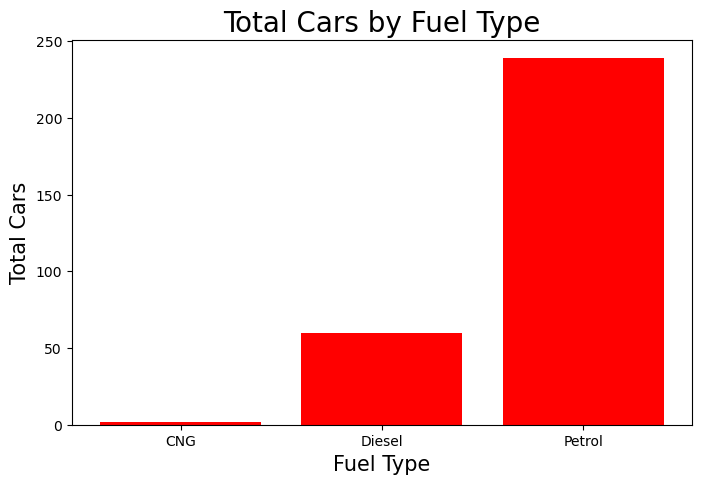

In [74]:
plt.figure(figsize=(8,5))
plt.bar(cars_by_fueltype.index,cars_by_fueltype.values,color='r')
plt.title("Total Cars by Fuel Type",fontsize=20)
plt.xlabel("Fuel Type",fontsize=15)
plt.ylabel("Total Cars",fontsize=15)
plt.show()

In [75]:
year_by_sellingprice=df.groupby("Year")["Selling_Price"].sum()
print(year_by_sellingprice)

Year
2003      2.60
2004      1.50
2005      9.95
2006      5.75
2007      0.32
2008      7.02
2009     16.90
2010     78.94
2011     45.13
2012     88.35
2013    116.85
2014    180.96
2015    361.55
2016    260.66
2017    217.32
2018      9.25
Name: Selling_Price, dtype: float64


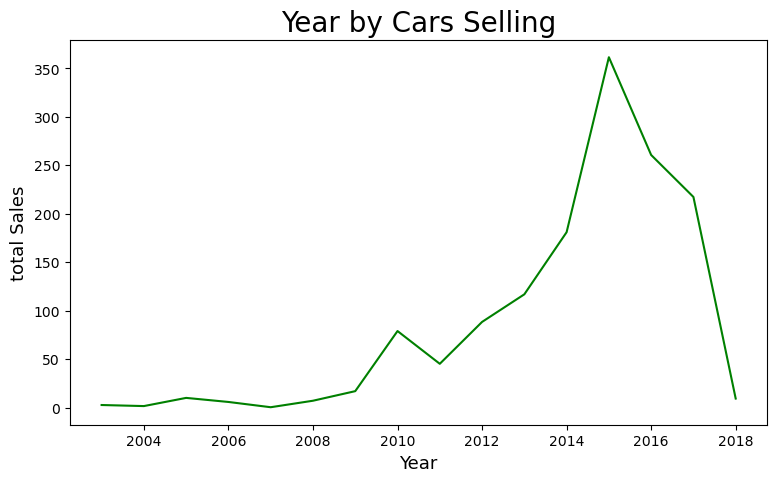

In [76]:
plt.figure(figsize=(9,5))
plt.plot(year_by_sellingprice.index,year_by_sellingprice.values,color='g')
plt.title("Year by Cars Selling",fontsize=20)
plt.xlabel("Year",fontsize=13)
plt.ylabel("total Sales",fontsize=13)
plt.show()

Feature Engineering

In [81]:
df=pd.get_dummies(df,drop_first=True)

X=df.drop(["Selling_Price","Owner"],axis=1)
y=df["Selling_Price"]